# Fase 5 — Avaliação

Backtest com origem móvel no P0131: 12 origens espaçadas de 14 dias, cada uma treinando com tudo até a origem e prevendo os 28 dias seguintes.

`erro_unidades = realizado − previsto` (positivo = faltou produto).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src.backtest import gerar_origens, rodar_backtest
from src.dados import carregar_demanda
from src.modelos import MODELOS
from src.preparacao import H, remover_descontinuados, serie_produto

SEED = 42
np.random.seed(SEED)
RAIZ = Path.cwd().parent
CAMINHO_FIGURAS = RAIZ / "relatorios" / "figuras"
CAMINHO_BACKTEST = RAIZ / "dados" / "processados" / "backtest_P0131.csv"
PRODUTO = "P0131"
pd.set_option("display.width", 180)

serie_p0131 = serie_produto(remover_descontinuados(carregar_demanda()), PRODUTO)
origens = gerar_origens(serie_p0131)
print(f"{len(origens)} origens | primeira {origens[0].date()} | última {origens[-1].date()} | passo {(origens[1] - origens[0]).days} dias")
for i, o in enumerate(origens, start=1):
    print(f"  origem {i:>2}: treino até {o.date()} ({len(serie_p0131.loc[:o])} dias) | teste {(o + pd.Timedelta(days=1)).date()} a {(o + pd.Timedelta(days=H)).date()}")

12 origens | primeira 2019-05-02 | última 2019-10-03 | passo 14 dias
  origem  1: treino até 2019-05-02 (851 dias) | teste 2019-05-03 a 2019-05-30
  origem  2: treino até 2019-05-16 (865 dias) | teste 2019-05-17 a 2019-06-13
  origem  3: treino até 2019-05-30 (879 dias) | teste 2019-05-31 a 2019-06-27
  origem  4: treino até 2019-06-13 (893 dias) | teste 2019-06-14 a 2019-07-11
  origem  5: treino até 2019-06-27 (907 dias) | teste 2019-06-28 a 2019-07-25
  origem  6: treino até 2019-07-11 (921 dias) | teste 2019-07-12 a 2019-08-08
  origem  7: treino até 2019-07-25 (935 dias) | teste 2019-07-26 a 2019-08-22
  origem  8: treino até 2019-08-08 (949 dias) | teste 2019-08-09 a 2019-09-05
  origem  9: treino até 2019-08-22 (963 dias) | teste 2019-08-23 a 2019-09-19
  origem 10: treino até 2019-09-05 (977 dias) | teste 2019-09-06 a 2019-10-03
  origem 11: treino até 2019-09-19 (991 dias) | teste 2019-09-20 a 2019-10-17
  origem 12: treino até 2019-10-03 (1005 dias) | teste 2019-10-04 a 2019-

In [2]:
if CAMINHO_BACKTEST.exists():
    resultados = pd.read_csv(CAMINHO_BACKTEST, parse_dates=["origem", "inicio_teste", "fim_teste"])
    print(f"Backtest carregado de {CAMINHO_BACKTEST.name}")
else:
    inicio = time.time()
    resultados = rodar_backtest(serie_p0131, MODELOS, origens)
    resultados.to_csv(CAMINHO_BACKTEST, index=False)
    print(f"Backtest executado em {time.time() - inicio:.0f} s e salvo em {CAMINHO_BACKTEST.name}")

print(f"Linhas: {len(resultados)} ({resultados['origem_n'].nunique()} origens × {resultados['modelo'].nunique()} modelos)")
print(f"Previsões negativas restantes: {(resultados['previsto_total'] < 0).sum()}")
print()
print(resultados[["origem_n", "inicio_teste", "modelo", "wmape", "real_total", "previsto_total", "erro_unidades", "dias_promo_teste"]]
      .round(2).to_string(index=False))

Backtest carregado de backtest_P0131.csv
Linhas: 60 (12 origens × 5 modelos)
Previsões negativas restantes: 0

 origem_n inicio_teste                  modelo  wmape  real_total  previsto_total  erro_unidades  dias_promo_teste
        1   2019-05-03      Naive sazonal (7d)  39.96      7765.0        10868.00       -3103.00                 0
        1   2019-05-03 Média 4 semanas (atual)  54.57      7765.0        12002.00       -4237.00                 0
        1   2019-05-03    Holt-Winters aditivo  43.35      7765.0        11131.18       -3366.18                 0
        1   2019-05-03 SARIMA (2,1,2)(1,1,1,7)  68.74      7765.0        13102.39       -5337.39                 0
        1   2019-05-03      SARIMAX + promoção  56.24      7765.0        12131.99       -4366.99                 0
        2   2019-05-17      Naive sazonal (7d)  14.11      8488.0         7512.00         976.00                 0
        2   2019-05-17 Média 4 semanas (atual)  32.11      8488.0        11104.00   

In [3]:
tabela_wmape = resultados.pivot(index=["origem_n", "inicio_teste"], columns="modelo", values="wmape")[list(MODELOS)]
print("WMAPE (%) por origem:")
print(tabela_wmape.round(2).to_string())
print()
tabela_erro = resultados.pivot(index="origem_n", columns="modelo", values="erro_unidades")[list(MODELOS)]
print("Erro do período em unidades (realizado − previsto; positivo = faltou):")
print(tabela_erro.round(0).to_string())

WMAPE (%) por origem:
modelo                 Naive sazonal (7d)  Média 4 semanas (atual)  Holt-Winters aditivo  SARIMA (2,1,2)(1,1,1,7)  SARIMAX + promoção
origem_n inicio_teste                                                                                                                
1        2019-05-03                 39.96                    54.57                 43.35                    68.74               56.24
2        2019-05-17                 14.11                    32.11                 13.36                    17.08               15.46
3        2019-05-31                 12.07                    17.72                 11.35                    12.64               11.73
4        2019-06-14                 13.71                    15.31                 11.93                     9.57                8.73
5        2019-06-28                 23.08                    21.27                 23.38                    17.15               12.22
6        2019-07-12                 12.2

## Comparação consolidada dos modelos nas 12 origens

`vies_global` segue a convenção do projeto: Σ(previsto − real) / Σreal (positivo = sobra). `erro_acumulado` segue a do backtest: realizado − previsto (positivo = falta).

In [4]:
def resumir(grupo):
    pior = grupo.loc[grupo["wmape"].idxmax()]
    return pd.Series({
        "wmape_medio": grupo["wmape"].mean(),
        "wmape_mediana": grupo["wmape"].median(),
        "wmape_desvio": grupo["wmape"].std(),
        "vies_global": (grupo["previsto_total"].sum() - grupo["real_total"].sum()) / grupo["real_total"].sum() * 100,
        "erro_acumulado": grupo["erro_unidades"].sum(),
        "pior_wmape": pior["wmape"],
        "origem_do_pior": int(pior["origem_n"]),
        "wmape_medio_sem_pior": grupo["wmape"].drop(pior.name).mean(),
    })

comparacao = resultados.groupby("modelo").apply(resumir, include_groups=False).sort_values("wmape_medio")
comparacao["ranking_com_pior"] = comparacao["wmape_medio"].rank().astype(int)
comparacao["ranking_sem_pior"] = comparacao["wmape_medio_sem_pior"].rank().astype(int)
print(comparacao.round(2).to_string())

                         wmape_medio  wmape_mediana  wmape_desvio  vies_global  erro_acumulado  pior_wmape  origem_do_pior  wmape_medio_sem_pior  ranking_com_pior  ranking_sem_pior
modelo                                                                                                                                                                              
Holt-Winters aditivo           15.36          11.69          9.81         1.85        -2055.74       43.35             1.0                 12.82                 1                 2
SARIMAX + promoção             15.50          11.98         13.28         6.86        -7618.48       56.24             1.0                 11.80                 2                 1
Naive sazonal (7d)             16.15          13.21          8.34         0.58         -645.00       39.96             1.0                 13.98                 3                 4
SARIMA (2,1,2)(1,1,1,7)        17.51          11.74         16.72         6.92        -7692.42 

## Da previsão à decisão: nível de serviço ótimo

In [5]:
from src.politica import PCT_CUSTO_FALTA, PCT_CUSTO_SOBRA, custos_unitarios, nivel_servico_otimo

preco_medio = serie_p0131["preco_medio"].mean()
custo_falta, custo_sobra = custos_unitarios(preco_medio)
nivel_servico = nivel_servico_otimo(custo_falta, custo_sobra)

print(f"1. Preço médio do {PRODUTO} na base:     R$ {preco_medio:.4f}")
print(f"2. Custo de faltar (Cu = {PCT_CUSTO_FALTA:.0%} do preço): R$ {custo_falta:.4f} por unidade")
print(f"3. Custo de sobrar (Co = {PCT_CUSTO_SOBRA:.0%} do preço):  R$ {custo_sobra:.4f} por unidade")
print(f"4. Razão Cu / Co:                      {custo_falta / custo_sobra:.1f}")
print(f"5. Nível de serviço ótimo Cu/(Cu+Co):  {nivel_servico:.4f} ({nivel_servico:.2%})")
print(f"6. Períodos em que aceita faltar:      {1 - nivel_servico:.2%}")

1. Preço médio do P0131 na base:     R$ 2.5870
2. Custo de faltar (Cu = 30% do preço): R$ 0.7761 por unidade
3. Custo de sobrar (Co = 2% do preço):  R$ 0.0517 por unidade
4. Razão Cu / Co:                      15.0
5. Nível de serviço ótimo Cu/(Cu+Co):  0.9375 (93.75%)
6. Períodos em que aceita faltar:      6.25%


## Estoque de segurança pela distribuição empírica dos erros do backtest

In [6]:
from src.politica import estoque_seguranca_empirico

modelos_finalistas = ["SARIMAX + promoção", "Holt-Winters aditivo"]
linhas_es = []
for nome in modelos_finalistas:
    erros = resultados.loc[resultados["modelo"] == nome].sort_values("origem_n")["erro_unidades"].values
    estoque_seg = estoque_seguranca_empirico(erros, nivel_servico)
    linhas_es.append({
        "modelo": nome,
        "estoque_seguranca_un": estoque_seg,
        "falta_so_previsao_%": (erros > 0).mean() * 100,
        "falta_com_es_%": (erros > estoque_seg).mean() * 100,
        "custo_es_por_periodo_R$": estoque_seg * custo_sobra,
    })
    print(f"{nome}: erros ordenados (realizado − previsto) = {np.sort(erros).round(0).tolist()}")

tabela_es = pd.DataFrame(linhas_es).set_index("modelo")
print(f"\nNível de serviço: {nivel_servico:.2%} | custo de sobrar: R$ {custo_sobra:.4f}/un")
print(tabela_es.round(2).to_string())
print(f"\nSensibilidade — mesmo cálculo com o nível arredondado para 93,8%:")
for nome in modelos_finalistas:
    erros = resultados.loc[resultados["modelo"] == nome, "erro_unidades"].values
    print(f"  {nome}: {estoque_seguranca_empirico(erros, 0.938):.2f} un")

SARIMAX + promoção: erros ordenados (realizado − previsto) = [-4367.0, -1592.0, -1040.0, -923.0, -735.0, -518.0, -154.0, -94.0, -80.0, 40.0, 559.0, 1286.0]
Holt-Winters aditivo: erros ordenados (realizado − previsto) = [-3366.0, -1659.0, -990.0, -951.0, -764.0, -29.0, 312.0, 422.0, 565.0, 848.0, 993.0, 2564.0]

Nível de serviço: 93.75% | custo de sobrar: R$ 0.0517/un
                      estoque_seguranca_un  falta_so_previsao_%  falta_com_es_%  custo_es_por_periodo_R$
modelo                                                                                                  
SARIMAX + promoção                  786.11                 25.0            8.33                    40.67
Holt-Winters aditivo               1484.25                 50.0            8.33                    76.80

Sensibilidade — mesmo cálculo com o nível arredondado para 93,8%:
  SARIMAX + promoção: 790.11 un
  Holt-Winters aditivo: 1492.89 un


## Critério 3 — simulação financeira da política de pedido

Pedido = previsão dos 28 dias + estoque de segurança do próprio modelo. Custo = falta × Cu + sobra × Co, em cada uma das 12 origens.

In [7]:
from src.politica import simular_politica

PERIODOS_ANO = 13
modelos_simulados = ["SARIMAX + promoção", "Holt-Winters aditivo", "Média 4 semanas (atual)"]

simulacao = pd.DataFrame({
    nome: simular_politica(resultados.loc[resultados["modelo"] == nome].sort_values("origem_n"),
                           nivel_servico, custo_falta, custo_sobra)
    for nome in modelos_simulados
}).T.sort_values("custo_medio_periodo_R$")
print(f"Nível de serviço {nivel_servico:.2%} | Cu R$ {custo_falta:.4f} | Co R$ {custo_sobra:.4f} | 12 origens")
print(simulacao.round(2).to_string())

Nível de serviço 93.75% | Cu R$ 0.7761 | Co R$ 0.0517 | 12 origens
                         estoque_seguranca_un  custo_medio_periodo_R$  falta_media_un  sobra_media_un  custo_falta_medio_R$  custo_sobra_medio_R$  origens_com_falta_%
SARIMAX + promoção                     786.11                  107.99           41.63         1462.62                 32.31                 75.68                 8.33
Média 4 semanas (atual)               2111.94                  147.11           10.26         2689.36                  7.96                139.15                 8.33
Holt-Winters aditivo                  1484.25                  160.15           89.98         1745.54                 69.83                 90.31                 8.33


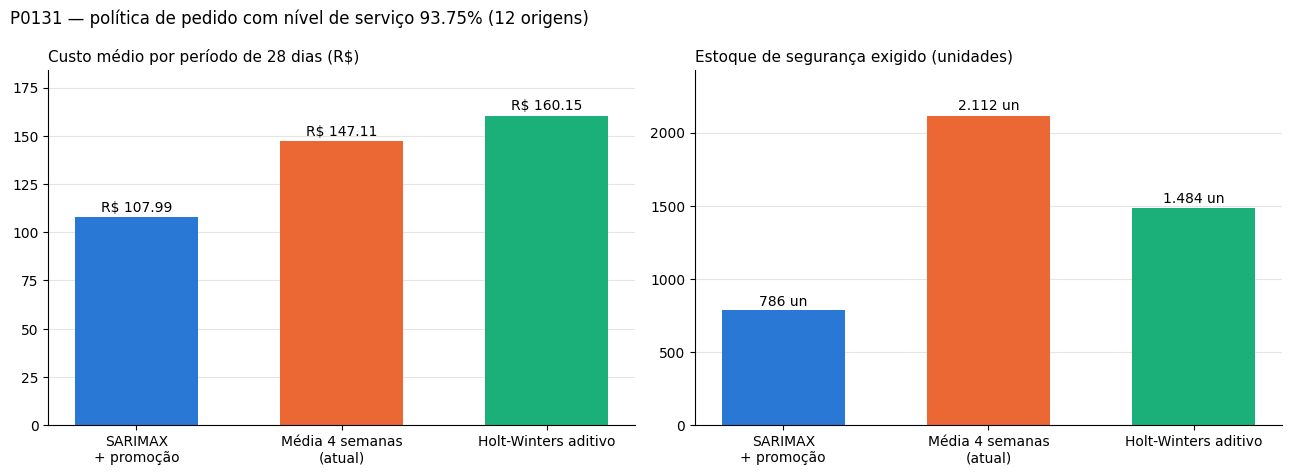

In [8]:
cores_modelo = {"SARIMAX + promoção": "#2a78d6", "Holt-Winters aditivo": "#1baf7a", "Média 4 semanas (atual)": "#eb6834"}
ordem = simulacao.index.tolist()
rotulos = [n.replace(" + ", "\n+ ").replace(" (", "\n(") for n in ordem]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, coluna, titulo, fmt in [
    (ax1, "custo_medio_periodo_R$", "Custo médio por período de 28 dias (R$)", "R$ {:.2f}"),
    (ax2, "estoque_seguranca_un", "Estoque de segurança exigido (unidades)", "{:,.0f} un"),
]:
    valores = simulacao[coluna]
    barras = ax.bar(rotulos, valores, color=[cores_modelo[n] for n in ordem], width=0.6)
    for barra, v in zip(barras, valores):
        ax.text(barra.get_x() + barra.get_width() / 2, v * 1.01, fmt.format(v).replace(",", "."), ha="center", va="bottom", fontsize=10)
    ax.set_title(titulo, fontsize=11, loc="left")
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(0, valores.max() * 1.15)
fig.suptitle(f"{PRODUTO} — política de pedido com nível de serviço {nivel_servico:.2%} (12 origens)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(CAMINHO_FIGURAS / "05_P0131_custo_e_estoque_seguranca.png", dpi=130)
plt.show()

In [9]:
atual = simulacao.loc["Média 4 semanas (atual)"]
for nome in ["SARIMAX + promoção", "Holt-Winters aditivo"]:
    m = simulacao.loc[nome]
    diferenca = atual["custo_medio_periodo_R$"] - m["custo_medio_periodo_R$"]
    print(f"{nome} vs processo atual")
    print(f"  Custo por período:   R$ {atual['custo_medio_periodo_R$']:.2f} -> R$ {m['custo_medio_periodo_R$']:.2f} "
          f"({'redução' if diferenca > 0 else 'aumento'} de R$ {abs(diferenca):.2f}; {-diferenca / atual['custo_medio_periodo_R$']:+.1%})")
    print(f"  Estoque de segurança: {atual['estoque_seguranca_un']:,.0f} un -> {m['estoque_seguranca_un']:,.0f} un "
          f"({m['estoque_seguranca_un'] - atual['estoque_seguranca_un']:+,.0f} un)")
    print(f"  Falta média:          {atual['falta_media_un']:.1f} un -> {m['falta_media_un']:.1f} un por período")
    print(f"  Economia anual ({PERIODOS_ANO} × 28 dias, só o {PRODUTO}): R$ {diferenca * PERIODOS_ANO:+.2f}")
    print(f"  Critério 3: {'CUMPRE' if diferenca > 0 else 'NÃO CUMPRE'}")
    print()

SARIMAX + promoção vs processo atual
  Custo por período:   R$ 147.11 -> R$ 107.99 (redução de R$ 39.12; -26.6%)
  Estoque de segurança: 2,112 un -> 786 un (-1,326 un)
  Falta média:          10.3 un -> 41.6 un por período
  Economia anual (13 × 28 dias, só o P0131): R$ +508.57
  Critério 3: CUMPRE

Holt-Winters aditivo vs processo atual
  Custo por período:   R$ 147.11 -> R$ 160.15 (aumento de R$ 13.04; +8.9%)
  Estoque de segurança: 2,112 un -> 1,484 un (-628 un)
  Falta média:          10.3 un -> 90.0 un por período
  Economia anual (13 × 28 dias, só o P0131): R$ -169.55
  Critério 3: NÃO CUMPRE

